# Modèle 2 — Alerte précoce : « ça va arriver »

**Membre 3 — Mobio Ivan Junior** · Étape 6 du pipeline

## L'idée en une phrase

En ne regardant que les **15 premières minutes** d'une session de charge, on prédit si elle va **finir en surchauffe** (au-delà de 45 °C), pour prévenir **avant** que ça arrive.

## Pourquoi c'est utile

Les seuils disent « ça dépasse **maintenant** ». Le modèle 1 dit « c'est plus chaud que prévu » — mais une fois la session terminée. Le modèle 2 est le seul à **anticiper** : il laisse le temps de réduire le courant ou d'arrêter la charge.

## Plan du notebook

| Étape | Contenu |
|---|---|
| 0 | Importer les bibliothèques |
| 1 | Charger les sessions |
| 2 | La question et l'étiquette |
| 3 | Qui peut-on évaluer ? (la règle des 15 minutes) |
| 4 | Les entrées : ce qu'on sait à la 15e minute |
| 5 | Séparer train / test par véhicule |
| 6 | Le piège des classes déséquilibrées |
| 7 | Les métriques de classification |
| 8 | Une référence simple : une règle sur la température à 15 min |
| 9 | Les 2 algorithmes et la validation croisée |
| 10 | Choisir le seuil de probabilité |
| 11 | Résultats sur les véhicules de test |
| 12 | Combien de minutes d'avance ? |
| 13 | Importance des variables |
| 14 | Voter et sauvegarder |
| 15 | Conclusions |

👉 **Exécuter les cellules dans l'ordre**, de haut en bas (Maj + Entrée).

> Le même code, regroupé en fonctions, est dans `src/models/alerte_precoce.py` (utilisé par `main.py`, la fusion et `tests/test_alerte_precoce.py`).

---
## Étape 0 — Importer les bibliothèques

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (confusion_matrix, precision_recall_curve, average_precision_score,
                             precision_score, recall_score, f1_score, fbeta_score)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.config import SESSIONS_PARQUET, PROCESSED_DIR, FIGURES_DIR, TEST_VEHICLES, RANDOM_STATE, TEMP_ALERTE
from src.models.alerte_precoce import algorithmes, seuil_f2, metriques, minutes_avant_surchauffe

pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Seuil de surchauffe :", TEMP_ALERTE, "°C | véhicules de test :", TEST_VEHICLES)

Seuil de surchauffe : 45 °C | véhicules de test : [17, 18, 19, 20]


### 🗺️ Vue d'ensemble : la ligne du temps d'une session

Le modèle décide à la **15e minute**. Une alerte est utile si la surchauffe arrive **plus tard** : le temps entre les deux est l'**avance** gagnée.

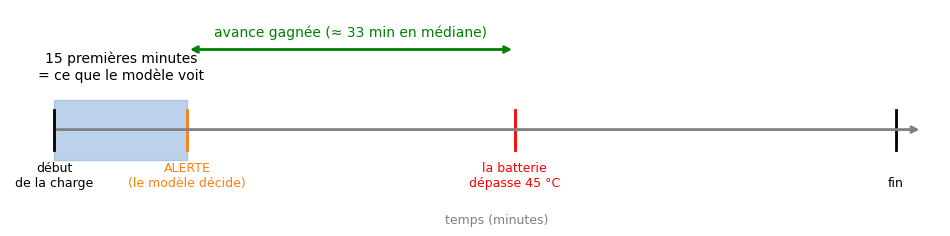

In [2]:
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.set_xlim(-5, 100); ax.set_ylim(0, 3); ax.axis("off")
ax.annotate("", xy=(98, 1.2), xytext=(0, 1.2), arrowprops=dict(arrowstyle="->", lw=2, color="grey"))
ax.axvspan(0, 15, ymin=0.25, ymax=0.55, color="#7aa6d6", alpha=0.5)
ax.text(7.5, 1.95, "15 premières minutes\n= ce que le modèle voit", ha="center", fontsize=10)
for x, texte, couleur in [(0, "début\nde la charge", "black"), (15, "ALERTE\n(le modèle décide)", "tab:orange"),
                          (52, "la batterie\ndépasse 45 °C", "red"), (95, "fin", "black")]:
    ax.plot([x, x], [0.9, 1.5], color=couleur, lw=2)
    ax.text(x, 0.35, texte, ha="center", fontsize=9, color=couleur)
ax.annotate("", xy=(52, 2.4), xytext=(15, 2.4), arrowprops=dict(arrowstyle="<->", color="green", lw=2))
ax.text(33.5, 2.6, "avance gagnée (≈ 33 min en médiane)", ha="center", color="green", fontsize=10)
ax.text(50, -0.2, "temps (minutes)", ha="center", fontsize=9, color="grey")
plt.savefig(FIGURES_DIR / "alerte_ligne_du_temps.png", dpi=120, bbox_inches="tight")
plt.show()

---
## Étape 1 — Charger les sessions

Une ligne = une session de charge (étape 5, `src/sessions.py`). Les colonnes `*_15min` y sont déjà calculées sur les 15 premières minutes de chaque session.

In [3]:
sessions = pd.read_parquet(SESSIONS_PARQUET)
print(f"{len(sessions):,} sessions, {sessions.vehicle_id.nunique()} véhicules")
sessions[["vehicle_id", "debut", "duree_min", "temp_debut", "temp_15min", "temp_max"]].head()

30,855 sessions, 20 véhicules


,vehicle_id,debut,duree_min,temp_debut,temp_15min,temp_max
0,1,2019-07-26 20:02:35,122.967,41,42,44
1,1,2019-07-27 04:06:56,100.333,39,41,43
2,1,2019-07-28 17:25:00,89.233,35,37,40
3,1,2019-07-29 11:31:06,188.117,36,36,40
4,1,2019-07-29 22:20:45,94.717,34,34,37


---
## Étape 2 — La question et l'étiquette

**Question :** la session va-t-elle finir au-delà de **45 °C** ?

**Étiquette** (`label_surchauffe`) : 1 si `temp_max` > 45 °C, sinon 0. C'est la règle des seuils (approche 1) : le modèle 2 apprend à **prévoir** ce que les seuils constateront plus tard.

> Ce n'est pas une étiquette de panne posée par un expert : c'est une étiquette **calculée** à partir de la mesure de température.

In [4]:
sessions["label_surchauffe"] = (sessions["temp_max"] > TEMP_ALERTE).astype(int)
sessions["label_surchauffe"].value_counts().rename(index={0: "normale (0)", 1: "surchauffe (1)"}).to_frame("sessions")

,sessions
label_surchauffe,
normale (0),30552
surchauffe (1),303


Les sessions en surchauffe sont-elles concentrées sur quelques véhicules ? (Si oui, le modèle risquerait d'apprendre à reconnaître des véhicules.)

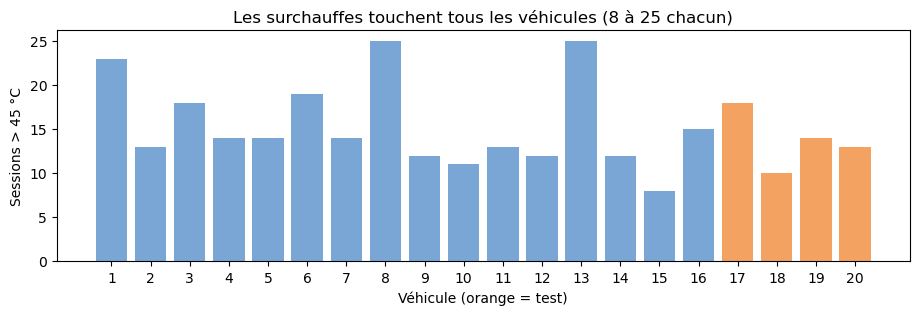

In [5]:
par_vehicule = sessions.groupby("vehicle_id")["label_surchauffe"].sum()
couleurs = ["#f4a261" if v in TEST_VEHICLES else "#7aa6d6" for v in par_vehicule.index]
plt.figure(figsize=(11, 3))
plt.bar(par_vehicule.index, par_vehicule.values, color=couleurs)
plt.xticks(par_vehicule.index)
plt.xlabel("Véhicule (orange = test)"); plt.ylabel("Sessions > 45 °C")
plt.title("Les surchauffes touchent tous les véhicules (8 à 25 chacun)")
plt.show()

**Lecture.** Tous les véhicules ont des surchauffes : le modèle peut apprendre un comportement **général**, valable pour un véhicule jamais vu. C'est la différence avec la cellule (90 % des cas sur le véhicule 9), pour laquelle l'équipe a retiré le modèle 2 (option D).

---
## Étape 3 — Qui peut-on évaluer ? La règle des 15 minutes

Trois cas :

| Cas | Que faire | Pourquoi |
|---|---|---|
| Session de **moins de 15 min** | pas de prédiction (vote 0) | il n'y a pas de fenêtre de 15 min à regarder |
| Déjà **au-delà de 45 °C à la 15e minute** | alerte immédiate (vote 1) | il n'y a plus rien à **anticiper** : la surchauffe est déjà là |
| Les autres | **le modèle décide** | c'est là qu'une alerte précoce a du sens |

Le modèle est entraîné et évalué uniquement sur le 3e groupe.

In [6]:
longue = sessions["session_longue"].astype(bool)
deja = longue & (sessions["temp_15min"] > TEMP_ALERTE)
evaluable = longue & ~deja

pd.DataFrame({
    "sessions": [int((~longue).sum()), int(deja.sum()), int(evaluable.sum())],
    "dont surchauffe": [int(sessions.loc[~longue, "label_surchauffe"].sum()),
                        int(sessions.loc[deja, "label_surchauffe"].sum()),
                        int(sessions.loc[evaluable, "label_surchauffe"].sum())],
}, index=["moins de 15 min", "déjà > 45 °C à 15 min", "évaluables (le modèle décide)"])

,sessions,dont surchauffe
moins de 15 min,633,2
déjà > 45 °C à 15 min,6,6
évaluables (le modèle décide),30216,295


In [7]:
pop = sessions[evaluable].copy()
print(f"Population du modèle : {len(pop):,} sessions, dont {pop.label_surchauffe.sum()} surchauffes ({pop.label_surchauffe.mean():.2%})")

Population du modèle : 30,216 sessions, dont 295 surchauffes (0.98%)


---
## Étape 4 — Les entrées : uniquement ce qu'on sait à la 15e minute

**Règle d'or :** le modèle ne doit voir **aucune information postérieure à la 15e minute**. Sinon il « tricherait » : par exemple, `temp_max` ou `duree_min` ne sont connus qu'à la fin de la session (raisonnement circulaire).

| Variable | Connue quand ? | Sens |
|---|---|---|
| `temp_15min` | à 15 min | température max pendant les 15 premières minutes |
| `vitesse_temp_15min` | à 15 min | vitesse de montée (°C/min) |
| `courant_moyen_15min` | à 15 min | courant moyen (A, négatif = charge) |
| `ecart_v_max_15min` | à 15 min | écart de tension max entre cellules |
| `soc_15min` | à 15 min | état de charge à la 15e minute |
| `temp_debut` | au départ | température au branchement |
| `soc_debut` | au départ | état de charge au branchement |
| `mois` | au départ | saison |

In [8]:
FEATURES = ["temp_15min", "vitesse_temp_15min", "courant_moyen_15min", "ecart_v_max_15min",
            "soc_15min", "temp_debut", "soc_debut", "mois"]
CIBLE = "label_surchauffe"
pop.groupby(CIBLE)[FEATURES].mean().T.rename(columns={0: "normale", 1: "surchauffe"})

label_surchauffe,normale,surchauffe
temp_15min,32.672,42.505
vitesse_temp_15min,0.080,0.056
courant_moyen_15min,-60.279,-68.068
ecart_v_max_15min,0.034,0.034
soc_15min,48.467,30.948
temp_debut,31.475,41.678
soc_debut,36.248,17.059
mois,7.236,7.590


**Lecture.** Les sessions qui finissent en surchauffe sont déjà **plus chaudes au départ** (≈ 42 °C contre 31 °C) **et à 15 min** (≈ 42,5 °C contre 32,7 °C). Elles démarrent aussi avec une batterie **plus vide** (SOC ≈ 17 % contre 36 %) : il reste plus d'énergie à charger, donc plus longtemps à chauffer.

Distribution de `temp_15min` selon le groupe :

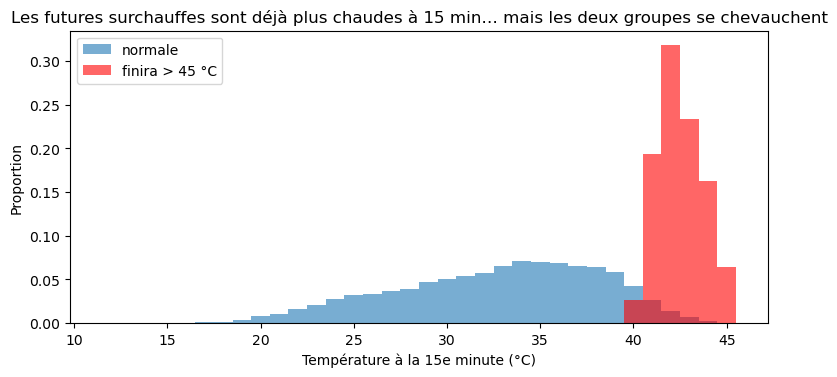

In [9]:
plt.figure(figsize=(9, 3.8))
bins = np.arange(pop.temp_15min.min(), pop.temp_15min.max() + 2) - 0.5
plt.hist(pop.loc[pop[CIBLE] == 0, "temp_15min"], bins=bins, alpha=0.6, label="normale", density=True)
plt.hist(pop.loc[pop[CIBLE] == 1, "temp_15min"], bins=bins, alpha=0.6, label="finira > 45 °C", density=True, color="red")
plt.xlabel("Température à la 15e minute (°C)"); plt.ylabel("Proportion")
plt.title("Les futures surchauffes sont déjà plus chaudes à 15 min… mais les deux groupes se chevauchent")
plt.legend(); plt.show()

**Lecture.** Les deux groupes se **chevauchent** entre 38 et 44 °C : la température à 15 min seule ne suffit pas à trancher. Le modèle doit combiner plusieurs indices (vitesse de montée, courant, SOC…).

---
## Étape 5 — Séparer train / test par véhicule

Comme pour le modèle 1 : 16 véhicules d'entraînement, 4 véhicules de test **jamais vus** (17 à 20).

In [10]:
est_test = pop["vehicle_id"].isin(TEST_VEHICLES)
train, test = pop[~est_test], pop[est_test]
X_train, y_train = train[FEATURES], train[CIBLE]
X_test, y_test = test[FEATURES], test[CIBLE]
print(f"Train : {len(train):,} sessions, {y_train.sum()} surchauffes")
print(f"Test  : {len(test):,} sessions, {y_test.sum()} surchauffes")

Train : 24,169 sessions, 242 surchauffes
Test  : 6,047 sessions, 53 surchauffes


---
## Étape 6 — Le piège des classes déséquilibrées

Seulement **≈ 1 %** des sessions finissent en surchauffe. Un « modèle » qui répond **toujours « normale »** aurait 99 % d'exactitude (*accuracy*)… et ne détecterait **aucune** surchauffe.

In [11]:
toujours_normal = np.zeros(len(y_test), dtype=int)
print(f"Exactitude du modèle « toujours normal » : {(toujours_normal == y_test).mean():.1%}")
print(f"Surchauffes détectées : {recall_score(y_test, toujours_normal):.0%}")

Exactitude du modèle « toujours normal » : 99.1%
Surchauffes détectées : 0%


➡️ **On n'utilise jamais l'exactitude ici.** Et on **rééquilibre** l'apprentissage pour que les rares surchauffes comptent autant que les nombreuses sessions normales :

| Algorithme | Paramètre | Effet |
|---|---|---|
| Random Forest | `class_weight="balanced_subsample"` | une erreur sur une surchauffe coûte ≈ 100 fois plus |
| XGBoost | `scale_pos_weight` = nb de normales / nb de surchauffes | même idée |

In [12]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Une surchauffe pèse {ratio:.0f} fois plus qu'une session normale")

Une surchauffe pèse 99 fois plus qu'une session normale


---
## Étape 7 — Les métriques de classification

Le modèle donne une **probabilité** de surchauffe. Avec un **seuil** (ex. 0,5), on la transforme en décision : alerte ou pas. On compte alors 4 cas — la **matrice de confusion** :

| | Prédit « normale » | Prédit « surchauffe » (alerte) |
|---|---|---|
| **Vraie normale** | VN : vrai négatif ✅ | FP : **fausse alerte** ⚠️ |
| **Vraie surchauffe** | FN : **surchauffe ratée** ❌ | VP : surchauffe détectée ✅ |

| Métrique | Formule | Question |
|---|---|---|
| **Rappel** | VP / (VP + FN) | parmi les vraies surchauffes, combien sont détectées ? |
| **Précision** | VP / (VP + FP) | parmi les alertes, combien sont justifiées ? |
| **F1** | moyenne harmonique de précision et rappel | équilibre des deux |
| **F2** | comme F1, mais le **rappel compte double** | notre critère : rater une surchauffe est plus grave qu'une fausse alerte |
| **PR-AUC** | aire sous la courbe précision-rappel | qualité du modèle **tous seuils confondus** (1 = parfait, ≈ 0,01 = hasard ici) |

**Pourquoi le rappel est prioritaire ?** Une surchauffe ratée peut abîmer la batterie ; une fausse alerte coûte seulement une vérification.

---
## Étape 8 — Une référence simple : une règle sur `temp_15min`

Avant le machine learning, on essaie la règle la plus simple : « alerte si `temp_15min` ≥ X °C ». On choisit X sur le train (meilleur F2). Si les modèles ne font pas mieux, ils sont inutiles.

In [13]:
seuil_regle = seuil_f2(y_train, train["temp_15min"])
m_regle = metriques(y_test, test["temp_15min"], seuil_regle)
print(f"Règle : alerte si temp_15min ≥ {seuil_regle:.0f} °C")
print(f"Test : rappel {m_regle['rappel']:.0%} ({m_regle['vp']}/{m_regle['vp'] + m_regle['fn']} surchauffes), "
      f"précision {m_regle['precision']:.0%} ({m_regle['fp']} fausses alertes)")

Règle : alerte si temp_15min ≥ 42 °C
Test : rappel 72% (38/53 surchauffes), précision 22% (138 fausses alertes)


---
## Étape 9 — Les 2 algorithmes et la validation croisée

On compare **Random Forest** et **XGBoost** (expliqués en détail dans le notebook du modèle 1), cette fois en **classification** : ils renvoient une probabilité de surchauffe.

Comme pour le modèle 1, la **validation croisée par véhicule** (`GroupKFold`, 4 plis) donne une probabilité *hors-échantillon* pour chaque session du train. Elle sert à choisir le meilleur algorithme (**PR-AUC**) et le seuil, sans toucher au test.

⏳ Environ 1 minute.

In [14]:
plis = GroupKFold(n_splits=4)
proba_oof, proba_test, modeles = {}, {}, {}

for nom, modele in algorithmes(y_train).items():
    proba_oof[nom] = cross_val_predict(modele, X_train, y_train, groups=train["vehicle_id"],
                                       cv=plis, method="predict_proba")[:, 1]
    modele.fit(X_train, y_train)
    modeles[nom] = modele
    proba_test[nom] = modele.predict_proba(X_test)[:, 1]
    print(f"✔ {nom:<14} PR-AUC validation croisée : {average_precision_score(y_train, proba_oof[nom]):.3f}")

meilleur = max(proba_oof, key=lambda n: average_precision_score(y_train, proba_oof[n]))
print("\nMeilleur algorithme :", meilleur)

✔ random_forest  PR-AUC validation croisée : 0.779


✔ xgboost        PR-AUC validation croisée : 0.804

Meilleur algorithme : xgboost


**Courbes précision-rappel (validation croisée).** Chaque point de la courbe correspond à un seuil différent. Plus la courbe est **haute et à droite**, meilleur est le modèle. La règle simple est très en dessous.

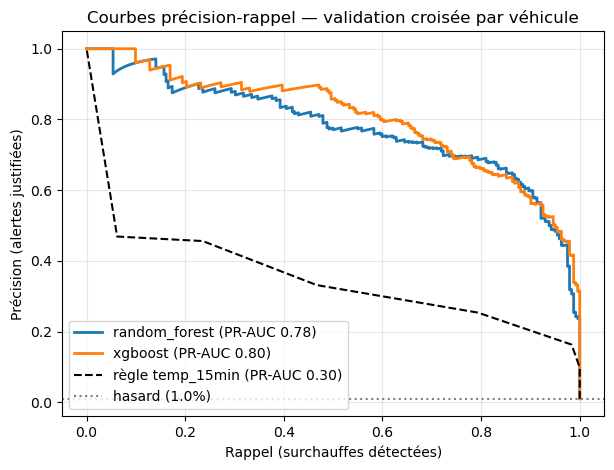

In [15]:
plt.figure(figsize=(7, 5))
for nom in proba_oof:
    p, r, _ = precision_recall_curve(y_train, proba_oof[nom])
    plt.plot(r, p, lw=2, label=f"{nom} (PR-AUC {average_precision_score(y_train, proba_oof[nom]):.2f})")
p, r, _ = precision_recall_curve(y_train, train["temp_15min"])
plt.plot(r, p, "k--", label=f"règle temp_15min (PR-AUC {average_precision_score(y_train, train['temp_15min']):.2f})")
plt.axhline(y_train.mean(), color="grey", ls=":", label=f"hasard ({y_train.mean():.1%})")
plt.xlabel("Rappel (surchauffes détectées)"); plt.ylabel("Précision (alertes justifiées)")
plt.title("Courbes précision-rappel — validation croisée par véhicule")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(FIGURES_DIR / "alerte_courbes_pr.png", dpi=120, bbox_inches="tight")
plt.show()

---
## Étape 10 — Choisir le seuil de probabilité

Le seuil par défaut (0,5) n'est pas adapté aux classes déséquilibrées. On choisit le seuil qui **maximise le F2** sur les probabilités hors-échantillon du train : un compromis qui favorise le rappel.

Le graphique montre comment précision, rappel et F2 évoluent quand on déplace le seuil.

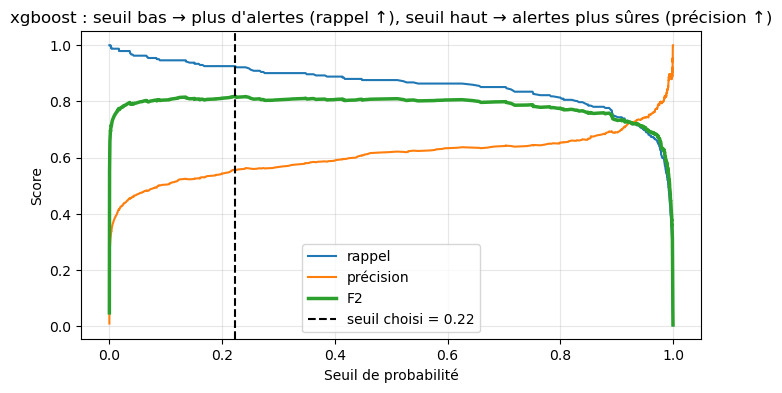

Seuil retenu : alerte si probabilité ≥ 0.223


In [16]:
p, r, s = precision_recall_curve(y_train, proba_oof[meilleur])
f2 = 5 * p * r / np.maximum(4 * p + r, 1e-12)
seuil = seuil_f2(y_train, proba_oof[meilleur])

plt.figure(figsize=(8, 4))
plt.plot(s, r[:-1], label="rappel"); plt.plot(s, p[:-1], label="précision"); plt.plot(s, f2[:-1], lw=2.5, label="F2")
plt.axvline(seuil, color="k", ls="--", label=f"seuil choisi = {seuil:.2f}")
plt.xlabel("Seuil de probabilité"); plt.ylabel("Score")
plt.title(f"{meilleur} : seuil bas → plus d'alertes (rappel ↑), seuil haut → alertes plus sûres (précision ↑)")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"Seuil retenu : alerte si probabilité ≥ {seuil:.3f}")

---
## Étape 11 — Résultats sur les véhicules de test

Mesure finale, sur les 4 véhicules jamais vus. Pour chaque approche, son propre seuil choisi sur le train.

In [17]:
lignes = [{"approche": "règle temp_15min", **metriques(y_test, test["temp_15min"], seuil_regle)}]
for nom in modeles:
    lignes.append({"approche": nom, **metriques(y_test, proba_test[nom], seuil_f2(y_train, proba_oof[nom]))})
resultats = pd.DataFrame(lignes).set_index("approche")
resultats[["rappel", "precision", "f1", "f2", "pr_auc", "vp", "fn", "fp"]].round(3)

,rappel,precision,f1,f2,pr_auc,vp,fn,fp
approche,,,,,,,,
règle temp_15min,0.717,0.216,0.332,0.490,0.269,38,15,138
random_forest,0.887,0.635,0.740,0.822,0.849,47,6,27
xgboost,0.925,0.590,0.721,0.831,0.880,49,4,34


Les matrices de confusion côte à côte :

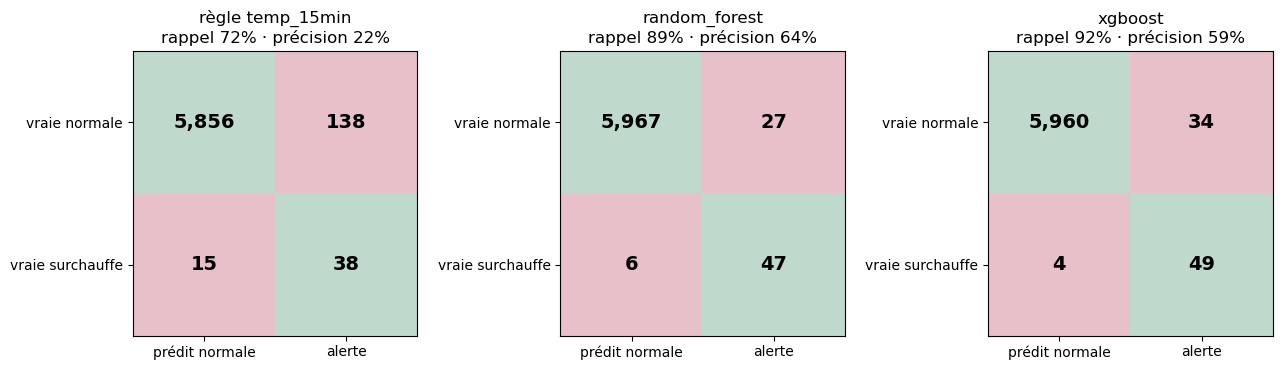

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (nom, r) in zip(axes, resultats.iterrows()):
    mat = np.array([[r.vn, r.fp], [r.fn, r.vp]]).astype(int)
    ax.imshow([[0, 1], [1, 0]], cmap="RdYlGn_r", alpha=0.25)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{mat[i, j]:,}", ha="center", va="center", fontsize=14, weight="bold")
    ax.set_xticks([0, 1], ["prédit normale", "alerte"]); ax.set_yticks([0, 1], ["vraie normale", "vraie surchauffe"])
    ax.set_title(f"{nom}\nrappel {r.rappel:.0%} · précision {r.precision:.0%}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alerte_matrices_confusion.png", dpi=120, bbox_inches="tight")
plt.show()

**Lecture.**
- La **règle simple** rate 15 surchauffes sur 53 et lance ≈ 140 fausses alertes.
- **XGBoost** détecte **49 surchauffes sur 53** (rappel ≈ 92 %), avec ≈ 4 fois moins de fausses alertes que la règle.
- Sur ≈ 6 000 sessions de test, une trentaine de fausses alertes reste un coût raisonnable pour ne presque rien rater.

---
## Étape 12 — Combien de minutes d'avance ?

Une alerte n'est utile que si elle arrive **avant** la surchauffe. On relit les mesures brutes nettoyées (étape 3) pour trouver, dans chaque session, **la minute où la batterie dépasse 45 °C pour la première fois**. L'avance gagnée = cette minute − 15.

⏳ Relit les 16 millions de mesures : environ 1 minute.

In [19]:
minutes_45 = minutes_avant_surchauffe(sessions)
alertes_test = proba_test[meilleur] >= seuil
detectees = test[(y_test == 1).to_numpy() & alertes_test]
avance = minutes_45.reindex(detectees["session_id"]).to_numpy() - 15

print(f"Surchauffes détectées sur le test : {len(detectees)}")
print(f"Avance : médiane {np.median(avance):.0f} min, moyenne {avance.mean():.0f} min, minimum {avance.min():.0f} min")

Surchauffes détectées sur le test : 49
Avance : médiane 33 min, moyenne 36 min, minimum 5 min


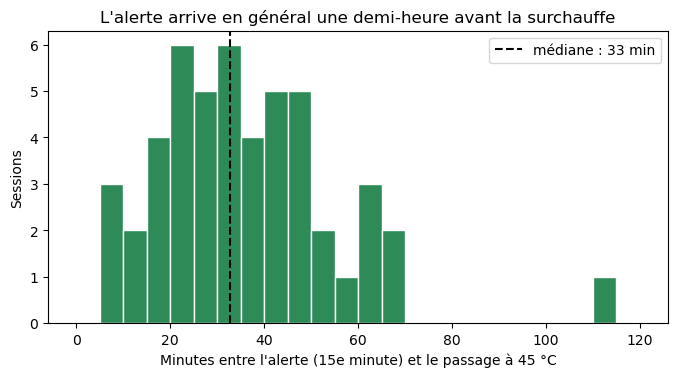

In [20]:
plt.figure(figsize=(8, 3.8))
plt.hist(avance, bins=range(0, int(avance.max()) + 10, 5), color="seagreen", edgecolor="white")
plt.axvline(np.median(avance), color="k", ls="--", label=f"médiane : {np.median(avance):.0f} min")
plt.xlabel("Minutes entre l'alerte (15e minute) et le passage à 45 °C"); plt.ylabel("Sessions")
plt.title("L'alerte arrive en général une demi-heure avant la surchauffe")
plt.legend()
plt.savefig(FIGURES_DIR / "alerte_avance.png", dpi=120, bbox_inches="tight")
plt.show()

**Un exemple réel.** La courbe de température d'une session de test détectée : on voit le moment de l'alerte et le moment de la surchauffe.

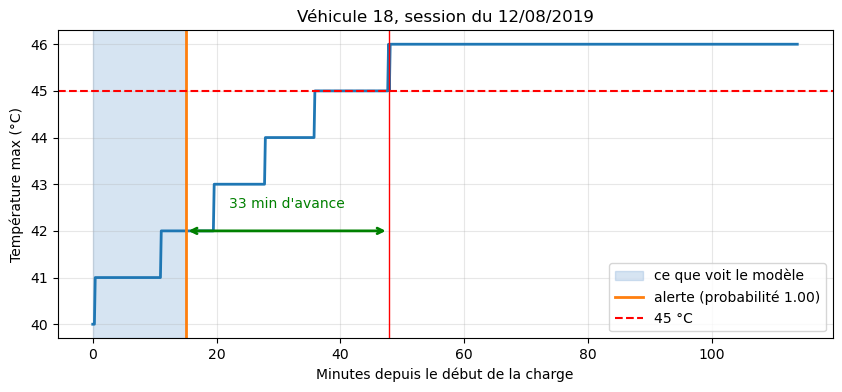

In [21]:
from src.config import CLEAN_PARQUET
from src.sessions import ajouter_session_id

exemple = detectees.assign(avance=avance).sort_values("avance").iloc[len(detectees) // 2]
mesures = pd.read_parquet(CLEAN_PARQUET, columns=["vehicle_id", "time", "temp_max"],
                          filters=[("vehicle_id", "==", int(exemple.vehicle_id))])
mesures = mesures[(mesures.time >= exemple.debut) & (mesures.time <= exemple.fin)]
minutes = (mesures.time - exemple.debut).dt.total_seconds() / 60

plt.figure(figsize=(10, 4))
plt.plot(minutes, mesures.temp_max, lw=2)
plt.axvspan(0, 15, color="#7aa6d6", alpha=0.3, label="ce que voit le modèle")
plt.axvline(15, color="tab:orange", lw=2, label=f"alerte (probabilité {proba_test[meilleur][test.index.get_loc(exemple.name)]:.2f})")
plt.axhline(TEMP_ALERTE, color="red", ls="--", label="45 °C")
plt.axvline(15 + exemple.avance, color="red", lw=1)
plt.annotate("", xy=(15 + exemple.avance, TEMP_ALERTE - 3), xytext=(15, TEMP_ALERTE - 3),
             arrowprops=dict(arrowstyle="<->", color="green", lw=2))
plt.text(15 + exemple.avance / 2, TEMP_ALERTE - 2.5, f"{exemple.avance:.0f} min d'avance", ha="center", color="green")
plt.xlabel("Minutes depuis le début de la charge"); plt.ylabel("Température max (°C)")
plt.title(f"Véhicule {int(exemple.vehicle_id)}, session du {exemple.debut:%d/%m/%Y}")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.savefig(FIGURES_DIR / "alerte_exemple_session.png", dpi=120, bbox_inches="tight")
plt.show()

---
## Étape 13 — Importance des variables

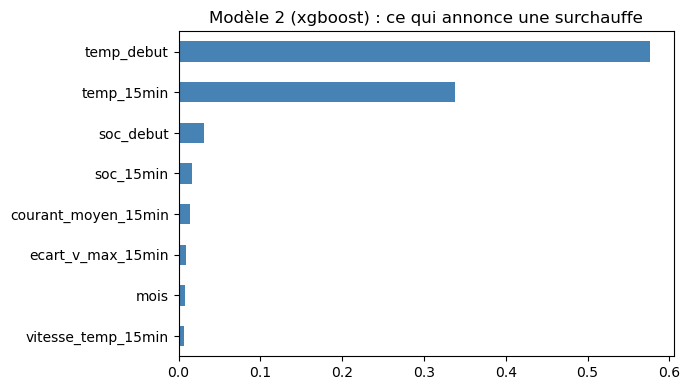

temp_debut             0.577
temp_15min             0.338
soc_debut              0.031
soc_15min              0.017
courant_moyen_15min    0.013
ecart_v_max_15min      0.009
mois                   0.008
vitesse_temp_15min     0.007
dtype: float32

In [22]:
importance = pd.Series(modeles[meilleur].feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 4), color="steelblue")
plt.title(f"Modèle 2 ({meilleur}) : ce qui annonce une surchauffe")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alerte_importance.png", dpi=120, bbox_inches="tight")
plt.show()
importance.sort_values(ascending=False).round(3)

**Lecture.** La **température au départ** et la **température à 15 min** dominent : une batterie déjà chaude a peu de marge avant 45 °C. Le **SOC de départ** vient ensuite : une batterie presque vide va charger longtemps. Les autres variables (SOC, courant, vitesse de montée) départagent les cas limites entre 38 et 44 °C.

---
## Étape 14 — Voter et sauvegarder

Vote pour **toutes** les sessions, selon le contrat de `TACHE.md` :

| Cas | `vote_alerte_precoce_surchauffe` | `raison_alerte_precoce` |
|---|---|---|
| probabilité ≥ seuil | 1 | risque de surchauffe prévu |
| déjà > 45 °C à 15 min | 1 | déjà > 45 °C à 15 min |
| session < 15 min | 0 (`ap_evaluable` = faux) | session < 15 min |
| sinon | 0 | |

In [23]:
modele_final = modeles[meilleur]
votes = sessions[["vehicle_id", "session_id"]].copy()
votes["proba_alerte_precoce"] = np.nan
votes.loc[evaluable, "proba_alerte_precoce"] = modele_final.predict_proba(sessions.loc[evaluable, FEATURES])[:, 1]
votes["vote_alerte_precoce_surchauffe"] = ((votes["proba_alerte_precoce"] >= seuil) | deja).astype(int)
votes["ap_evaluable"] = evaluable | deja
votes["raison_alerte_precoce"] = np.select(
    [deja, votes["vote_alerte_precoce_surchauffe"].eq(1), ~(evaluable | deja)],
    ["déjà > 45 °C à 15 min", "risque de surchauffe prévu", "session < 15 min"], default="")

votes["raison_alerte_precoce"].value_counts()

raison_alerte_precoce
                              29717
session < 15 min                633
risque de surchauffe prévu      499
déjà > 45 °C à 15 min             6
Name: count, dtype: int64

In [24]:
chemin = PROCESSED_DIR / "votes_alerte_precoce.parquet"
votes.to_parquet(chemin, index=False)
print("Votes enregistrés :", chemin, votes.shape)

Votes enregistrés : C:\Users\hp\Documents\HESTIM 2\PROJET PISTE\battery-charging-data-of-on-road-electric-vehicles-main\Dataset_automobile\data\processed\votes_alerte_precoce.parquet (30855, 6)


---
## Étape 15 — Conclusions

| | Règle `temp_15min` | **XGBoost (retenu)** |
|---|---|---|
| Surchauffes détectées (test) | 38 / 53 (72 %) | **49 / 53 (92 %)** |
| Alertes justifiées (précision) | ≈ 22 % | ≈ 59 % |
| Fausses alertes (≈ 6 000 sessions de test) | 138 | 34 |
| PR-AUC (test) | 0,27 | **0,88** |
| Avance médiane | — | **≈ 33 min** avant 45 °C |

**Apport du modèle 2 :** c'est la seule approche qui **anticipe**. À la 15e minute, il signale 9 surchauffes sur 10, environ une demi-heure avant qu'elles arrivent.

**Limites :**
- L'étiquette vient du seuil de 45 °C : le modèle prévoit un dépassement de seuil, pas une panne confirmée.
- Le seuil de probabilité (F2) favorise le rappel : environ 4 alertes sur 10 sont de fausses alertes — c'est un choix, que la fusion par vote tempère.
- Surchauffe uniquement : pour la cellule, 90 % des cas viennent du véhicule 9 (option D).